# Лабораторная работа №4: Байесовская сеть

**Цель:** представить зависимости между случайными величинами байесовской сетью, самостоятельно построить структуру графа и выполнить вероятностный вывод при появлении дополнительной информации (evidence).

## 1. Настройки эксперимента

Все настройки собраны в одном месте.

In [1]:
import textwrap
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from pgmpy.estimators import PC, HillClimbSearch
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE

DATA_PATH = "cancer.csv"
TARGET = "Cancer"
PSEUDO_COUNT = 1                      # сглаживание Лапласа: +1 к каждой ячейке счётчика
REMOVED_EDGE = ("Smoker", "Cancer")   # ребро для анализа структуры
PC_SIGNIFICANCE = 0.05                # уровень значимости тестов условной независимости

# Порядок добавления информации в эксперименте с evidence
EVIDENCE_STEPS = [
    ("ничего не известно", {}),
    ("+ курит", {"Smoker": "True"}),
    ("+ высокое загрязнение", {"Pollution": "high"}),
    ("+ рентген положительный", {"Xray": "positive"}),
    ("+ одышка", {"Dyspnoea": "True"}),
]

# Оформление
ROLE_COLORS = {"фактор риска": "#eda100", "заболевание": "#e34948", "симптом / обследование": "#2a78d6"}
ROLES = {"Pollution": "фактор риска", "Smoker": "фактор риска", "Cancer": "заболевание",
         "Xray": "симптом / обследование", "Dyspnoea": "симптом / обследование"}
POS = {"Pollution": (0, 2), "Smoker": (2, 2), "Cancer": (1, 1), "Xray": (0, 0), "Dyspnoea": (2, 0)}
NODE_LABELS = {"Pollution": "Pollution\nзагрязнение", "Smoker": "Smoker\nкурение", "Cancer": "Cancer\nрак лёгких",
               "Xray": "Xray\nрентген", "Dyspnoea": "Dyspnoea\nодышка"}
COLORS = {"mle": "#eb6834", "laplace": "#2a78d6", "data": "#898781"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

## 2. Данные

**Датасет** `cancer.csv` — 1000 пациентов, у каждого пять бинарных признаков, связанных с раком лёгких. Предметная область не требует специальных знаний: факторы риска → болезнь → симптомы.

**Один объект** — один человек, для которого известны условия жизни, привычка курить, наличие рака лёгких и результаты обследования.

| Переменная | Значения | Смысл |
|---|---|---|
| `Pollution` | low / high | уровень загрязнения воздуха в месте проживания |
| `Smoker` | True / False | курит ли человек |
| `Cancer` | True / False | есть ли рак лёгких |
| `Xray` | positive / negative | результат рентгена грудной клетки (есть ли затемнение) |
| `Dyspnoea` | True / False | есть ли одышка |

**Какие зависимости можно ожидать.** Курение и загрязнённый воздух — известные факторы риска рака лёгких, поэтому `Cancer` должен зависеть от `Smoker` и `Pollution`. Рак проявляется при обследовании: опухоль видна на рентгене и мешает дышать, поэтому `Xray` и `Dyspnoea` должны зависеть от `Cancer`. При этом одышка и положительный рентген бывают и без рака, так что связи вероятностные, а не жёсткие.

> Датасет учебный (синтетический): строки сгенерированы по классической учебной схеме «рак лёгких» (Korb & Nicholson). Поэтому зависимости в нём упрощённые, без реальных медицинских нюансов.

In [2]:
raw = pd.read_csv(DATA_PATH, index_col=0)
print("Размер:", raw.shape)
print("Типы:", raw.dtypes.astype(str).to_dict())
display(raw.head())

Размер: (1000, 5)
Типы: {'Pollution': 'str', 'Smoker': 'bool', 'Cancer': 'bool', 'Xray': 'str', 'Dyspnoea': 'bool'}


,Pollution,Smoker,Cancer,Xray,Dyspnoea
0,low,False,False,negative,False
1,low,False,False,negative,False
2,low,False,False,positive,True
3,low,False,False,positive,True
4,low,False,False,negative,False


## 3. Подготовка данных

Проверяем пропуски, распределения, редкие категории и то, сколько наблюдений приходится на каждую комбинацию родителей — именно по этим комбинациям будут оцениваться таблицы условных вероятностей.

In [3]:
print("Пропущенных значений:", raw.isna().sum().to_dict())
print("Полностью одинаковых строк:", raw.duplicated().sum(), "— это нормально: 5 бинарных признаков дают всего 32 комбинации")

# pgmpy работает с категориями: приводим всё к строкам, состояния остаются читаемыми
data = raw.astype(str)

shares = pd.concat(
    {col: data[col].value_counts().rename("n").to_frame().assign(доля=lambda t: t["n"] / len(data))
     for col in data.columns}
)
display(shares.round(3))

Пропущенных значений: {'Pollution': 0, 'Smoker': 0, 'Cancer': 0, 'Xray': 0, 'Dyspnoea': 0}
Полностью одинаковых строк: 979 — это нормально: 5 бинарных признаков дают всего 32 комбинации


n   доля
Pollution low       889  0.889
          high      111  0.111
Smoker    False     720  0.720
          True      280  0.280
Cancer    False     991  0.991
          True        9  0.009
Xray      negative  787  0.787
          positive  213  0.213
Dyspnoea  False     689  0.689
          True      311  0.311

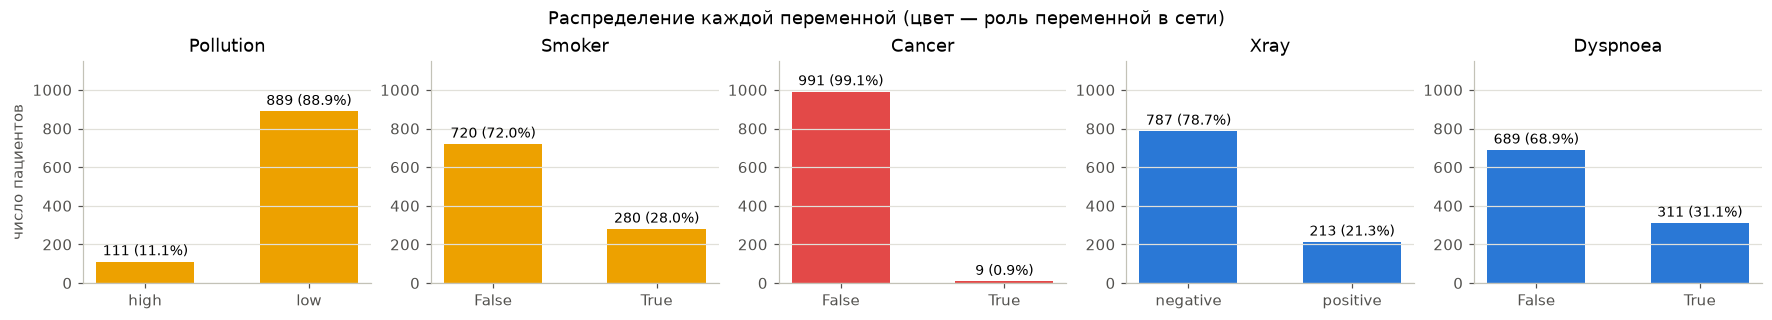

In [4]:
fig, axes = plt.subplots(1, len(data.columns), figsize=(16, 2.8), layout="constrained")
for ax, col in zip(axes, data.columns):
    counts = data[col].value_counts().sort_index()
    bars = ax.bar(counts.index, counts.values, color=ROLE_COLORS[ROLES[col]], width=0.6)
    ax.bar_label(bars, labels=[f"{v} ({v / len(data):.1%})" for v in counts.values], fontsize=9, padding=2)
    ax.set_title(col)
    ax.set_ylim(0, len(data) * 1.15)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("число пациентов")
fig.suptitle("Распределение каждой переменной (цвет — роль переменной в сети)")
plt.show()

In [5]:
# Сколько наблюдений приходится на каждую комбинацию родителей Cancer
cancer_counts = (data.groupby(["Pollution", "Smoker"])["Cancer"]
                 .agg(n="size", рак=lambda s: (s == "True").sum()).reset_index())
cancer_counts["доля рака"] = cancer_counts["рак"] / cancer_counts["n"]
display(cancer_counts.round(4))

# Сколько наблюдений есть для оценки симптомов у больных и здоровых
symptom_counts = pd.DataFrame({
    "n": data.groupby("Cancer").size(),
    "Xray = positive": data.groupby("Cancer")["Xray"].apply(lambda s: (s == "positive").sum()),
    "Dyspnoea = True": data.groupby("Cancer")["Dyspnoea"].apply(lambda s: (s == "True").sum()),
})
display(symptom_counts)

# Есть ли связь курения с одышкой у здоровых (без рака)?
healthy = data[data["Cancer"] == "False"]
print("Доля одышки у здоровых, по курению:")
display(pd.crosstab(healthy["Smoker"], healthy["Dyspnoea"], normalize="index").round(3))

,Pollution,Smoker,n,рак,доля рака
0,high,False,83,2,0.0241
1,high,True,28,0,0.0000
2,low,False,637,1,0.0016
3,low,True,252,6,0.0238


,n,Xray = positive,Dyspnoea = True
Cancer,,,
False,991,204,305
True,9,9,6


Доля одышки у здоровых, по курению:


Dyspnoea,False,True
Smoker,,
False,0.688,0.312
True,0.704,0.296


**Выводы по подготовке данных.**

* **Пропусков нет**, все признаки уже категориальные. Одинаковые строки — не ошибка: у пяти бинарных признаков всего 32 возможных комбинации.
* **Дискретизация не нужна**: непрерывных признаков нет. `Pollution` в исходных данных уже разбит на две категории. Это грубая шкала («умеренное» загрязнение отдельно не выделить), но более подробной у нас нет.
* **Число состояний** у всех переменных — 2. Таблица `P(Cancer | Pollution, Smoker)` имеет 2² = 4 комбинации родителей, у симптомов — по 2. Это немного для 1000 наблюдений. Если бы у каждого родителя было по 5 состояний, комбинаций было бы уже 25, и на многие из них не хватило бы данных.
* **Главная проблема — редкая категория `Cancer = True`: всего 9 случаев из 1000 (0.9%).** Важен не общий размер датасета, а частоты комбинаций родителей:
  * для пары `Pollution = high, Smoker = True` есть всего 28 человек и **ни одного** случая рака;
  * вероятности симптомов у больных оцениваются всего по 9 пациентам (рентген положительный у всех 9).
* **Наблюдений достаточно** для распределений `Pollution`, `Smoker` и для симптомов у здоровых (сотни случаев в каждой ячейке), но **мало** для всего, что касается больных раком. Поэтому в разделе 6 сравним оценку по частотам (MLE) со сглаживанием Лапласа.

## 4. Вопросы к модели

Формулируем вопросы **до построения сети**:

1. **Факторы риска.** Насколько курение повышает вероятность рака лёгких? Усиливается ли эффект, если человек ещё и живёт в загрязнённом районе?
   `P(Cancer)` → `P(Cancer | Smoker)` → `P(Cancer | Smoker, Pollution = high)`.
2. **Диагностика.** Насколько вероятен рак, если рентген положительный? Что меняется, если вдобавок есть одышка? Насколько успокаивает отрицательный рентген?
   `P(Cancer | Xray = positive)`, `P(Cancer | Xray = positive, Dyspnoea)`, `P(Cancer | Xray = negative)`.
3. **Explaining away.** У пациента рак. Насколько вероятно, что он курит? Меняется ли ответ, если известно, что он живёт в загрязнённом районе?
   `P(Smoker)` → `P(Smoker | Cancer)` → `P(Smoker | Cancer, Pollution = high)`.
4. **Косвенная связь.** Повышает ли курение вероятность одышки?
   `P(Dyspnoea)` → `P(Dyspnoea | Smoker)`.

## 5. Построение графа

### Рёбра сети

| Ребро | Почему предполагается зависимость | Почему такое направление |
|---|---|---|
| `Smoker → Cancer` | Курение — основной известный фактор риска рака лёгких: канцерогены табачного дыма повреждают клетки лёгких. | Привычка курить появляется раньше болезни и не является её следствием. |
| `Pollution → Cancer` | Загрязнённый воздух — второй фактор риска. | Загрязнение — внешнее условие места проживания, болезнь человека на него не влияет. |
| `Cancer → Xray` | Опухоль даёт затемнение на рентгеновском снимке. | Снимок фиксирует состояние лёгких, а не наоборот. |
| `Cancer → Dyspnoea` | Опухоль уменьшает рабочий объём лёгких и вызывает одышку. | Симптом — следствие болезни. |

### Рёбра, которые мы рассмотрели и не добавили

* **`Pollution — Smoker`.** Нет содержательной причины, по которой загрязнение воздуха заставляло бы курить (или наоборот). Факторы риска считаем независимыми.
* **`Smoker → Dyspnoea`, `Smoker → Xray`.** У реальных курильщиков одышка бывает и без рака (например, при бронхите). Но других болезней лёгких в наборе переменных нет, и наша гипотеза — курение влияет на симптомы только через рак. Это согласуется с данными: в разделе 3 у здоровых курящих и некурящих доля одышки практически одинакова (30% и 31%), так что прямое ребро не нужно.
* **`Xray — Dyspnoea`.** Два симптома одного заболевания связаны между собой только через общую причину. У прямой связи между снимком и одышкой нет механизма.

Ребро не добавлялось только потому, что признаки коррелируют: у каждого ребра есть содержательный механизм.

Граф ацикличный (DAG): True
Родители: {'Smoker': [], 'Pollution': [], 'Cancer': ['Pollution', 'Smoker'], 'Xray': ['Cancer'], 'Dyspnoea': ['Cancer']}


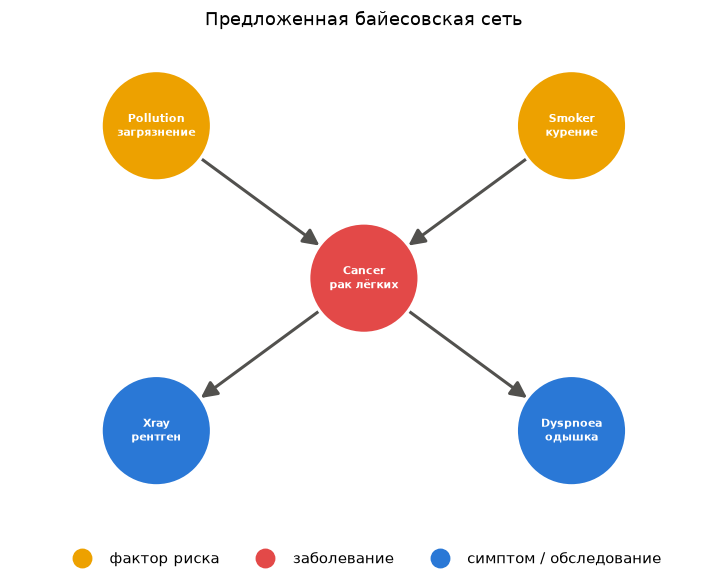

In [6]:
EDGES = [
    ("Smoker", "Cancer"),
    ("Pollution", "Cancer"),
    ("Cancer", "Xray"),
    ("Cancer", "Dyspnoea"),
]

dag = nx.DiGraph(EDGES)
print("Граф ацикличный (DAG):", nx.is_directed_acyclic_graph(dag))
print("Родители:", {node: sorted(dag.predecessors(node)) for node in nx.topological_sort(dag)})


def draw_network(ax, edges, title, undirected=()):
    graph = nx.DiGraph()
    graph.add_nodes_from(POS)
    graph.add_edges_from(edges)
    nx.draw_networkx_nodes(graph, POS, ax=ax, node_size=5200,
                           node_color=[ROLE_COLORS[ROLES[n]] for n in graph.nodes], edgecolors="white", linewidths=2)
    nx.draw_networkx_labels(graph, POS, labels=NODE_LABELS, ax=ax, font_size=7.5, font_color="white",
                            font_weight="bold")
    undirected_pairs = {tuple(sorted(edge)) for edge in undirected}
    directed = [edge for edge in edges if tuple(sorted(edge)) not in undirected_pairs]
    nx.draw_networkx_edges(graph, POS, edgelist=directed, ax=ax, node_size=5200, arrowsize=22, width=2,
                           edge_color="#52514e")
    nx.draw_networkx_edges(nx.Graph(list(undirected)), POS, edgelist=list(undirected), ax=ax, node_size=5200,
                           width=2, edge_color="#52514e", style="dashed")
    ax.set_title(title)
    ax.set_xlim(-0.7, 2.7)
    ax.set_ylim(-0.6, 2.6)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(6.5, 5.2), layout="constrained")
draw_network(ax, EDGES, "Предложенная байесовская сеть")
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="none", markersize=12, color=color, label=role)
                   for role, color in ROLE_COLORS.items()], loc="lower center", bbox_to_anchor=(0.5, -0.12),
          ncol=3, frameon=False)
plt.show()

**Факторизация.** Граф определяет, какие локальные вероятности нужно перемножить, чтобы получить совместное распределение:

$$P(Pollution, Smoker, Cancer, Xray, Dyspnoea) = P(Pollution)\,P(Smoker)\,P(Cancer \mid Pollution, Smoker)\,P(Xray \mid Cancer)\,P(Dyspnoea \mid Cancer)$$

Для бинарных переменных это **1 + 1 + 4 + 2 + 2 = 10 свободных параметров** вместо 2⁵ − 1 = 31 для полной таблицы совместного распределения.

**Три базовые структуры** в нашем графе:
* **цепь** `Smoker → Cancer → Xray`: если `Cancer` известен, он блокирует путь, и `Smoker ⟂ Xray | Cancer`;
* **развилка** `Xray ← Cancer → Dyspnoea`: при известном `Cancer` симптомы независимы, `Xray ⟂ Dyspnoea | Cancer`;
* **коллайдер** `Pollution → Cancer ← Smoker`: пока `Cancer` неизвестен, путь закрыт и `Pollution ⟂ Smoker`. Наблюдение `Cancer` (или его потомков — симптомов) открывает путь, и факторы риска становятся зависимыми. На этом основан explaining away (вопрос 3).

Полный список условных независимостей, которые следуют из графа по d-разделению:

In [7]:
model = DiscreteBayesianNetwork(EDGES)
for independence in sorted(str(i) for i in model.get_independencies().get_assertions()
                           if len(i.event1) == 1 and len(i.event2) == 1):
    print("  ", independence)

   (Dyspnoea ⟂ Pollution | Cancer)
   (Dyspnoea ⟂ Smoker | Cancer)
   (Dyspnoea ⟂ Xray | Cancer)
   (Pollution ⟂ Smoker)
   (Pollution ⟂ Xray | Cancer)
   (Smoker ⟂ Xray | Cancer)


## 6. Условные вероятности

При заданном графе каждая таблица условных вероятностей (CPT) оценивается по частотам. Сравниваем два способа:

* **MLE:** $\hat P(X = x \mid Pa(X) = u) = \dfrac{N(x, u)}{N(u)}$ — просто доля в данных. Если событие ни разу не встретилось, получаем 0;
* **сглаживание Лапласа:** $\hat P(X = x \mid Pa(X) = u) = \dfrac{N(x, u) + 1}{N(u) + 2}$ — к каждой ячейке счётчика добавляется 1 (для двух состояний в знаменателе +2). Нулей не бывает.

In [8]:
def fit_network(edges, estimator):
    network = DiscreteBayesianNetwork(edges)
    network.add_nodes_from(data.columns)
    network.fit(data, estimator=estimator)
    return network


def cpd_frame(cpd):
    # CPT как DataFrame: строки — состояния переменной, столбцы — комбинации родителей
    variable, parents = cpd.variables[0], cpd.variables[1:]
    values = cpd.get_values()
    index = pd.Index(cpd.state_names[variable], name=variable)
    if not parents:
        return pd.DataFrame(values, index=index, columns=["P"])
    if len(parents) == 1:
        return pd.DataFrame(values, index=index, columns=pd.Index(cpd.state_names[parents[0]], name=parents[0]))
    columns = pd.MultiIndex.from_product([cpd.state_names[p] for p in parents], names=parents)
    return pd.DataFrame(values, index=index, columns=columns)


model_mle = fit_network(EDGES, DiscreteMLE())
model = fit_network(EDGES, DiscreteBayesianEstimator(prior_type="dirichlet", pseudo_counts=PSEUDO_COUNT))

# Проверка: граф ацикличен, а суммы в каждом столбце каждой CPT равны 1
print("Модели корректны:", model.check_model(), model_mle.check_model())

Модели корректны: True True


In [9]:
cancer_cpts = pd.DataFrame({
    "наблюдений": cancer_counts.set_index(["Pollution", "Smoker"])["n"],
    "случаев рака": cancer_counts.set_index(["Pollution", "Smoker"])["рак"],
    "MLE": cpd_frame(model_mle.get_cpds("Cancer")).loc["True"],
    "Лаплас": cpd_frame(model.get_cpds("Cancer")).loc["True"],
})
print("P(Cancer = True | Pollution, Smoker)")
display(cancer_cpts.round(4))

symptom_rows = []
for variable, state in [("Xray", "positive"), ("Dyspnoea", "True")]:
    for cancer in ["False", "True"]:
        symptom_rows.append({
            "вероятность": f"P({variable}={state} | Cancer={cancer})",
            "наблюдений": int(symptom_counts.loc[cancer, "n"]),
            "MLE": cpd_frame(model_mle.get_cpds(variable)).loc[state, cancer],
            "Лаплас": cpd_frame(model.get_cpds(variable)).loc[state, cancer],
        })
display(pd.DataFrame(symptom_rows).set_index("вероятность").round(4))

P(Cancer = True | Pollution, Smoker)


наблюдений  случаев рака     MLE  Лаплас
Pollution Smoker                                          
high      False           83             2  0.0241  0.0353
          True            28             0  0.0000  0.0333
low       False          637             1  0.0016  0.0031
          True           252             6  0.0238  0.0276

,наблюдений,MLE,Лаплас
вероятность,,,
P(Xray=positive | Cancer=False),991,0.2059,0.2064
P(Xray=positive | Cancer=True),9,1.0000,0.9091
P(Dyspnoea=True | Cancer=False),991,0.3078,0.3082
P(Dyspnoea=True | Cancer=True),9,0.6667,0.6364


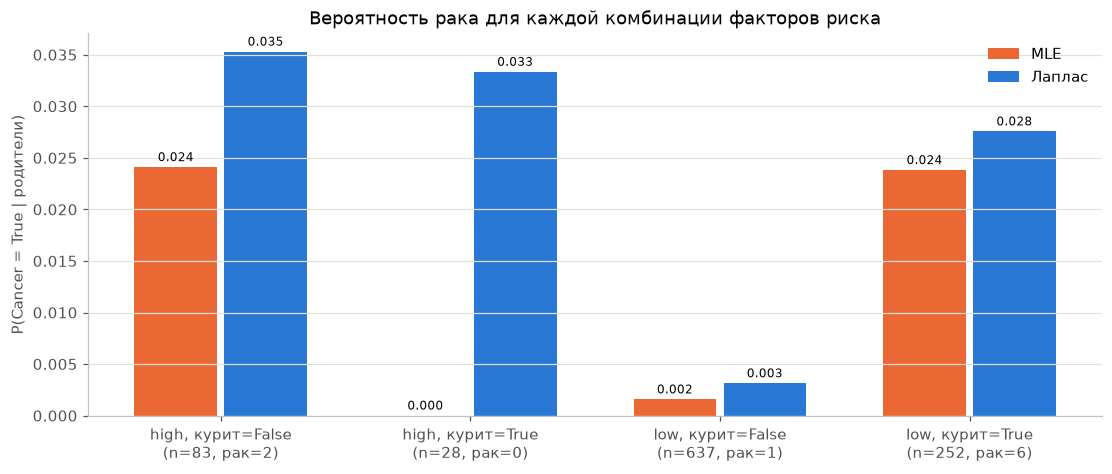

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
labels = [f"{p}, курит={s}\n(n={n}, рак={k})" for (p, s), n, k in
          zip(cancer_cpts.index, cancer_cpts["наблюдений"], cancer_cpts["случаев рака"])]
x = np.arange(len(cancer_cpts))
width = 0.36
for offset, column, color in [(-width / 2, "MLE", COLORS["mle"]), (width / 2, "Лаплас", COLORS["laplace"])]:
    bars = ax.bar(x + offset, cancer_cpts[column], width=width * 0.92, color=color, label=column)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in cancer_cpts[column]], fontsize=8, padding=2)
ax.set_xticks(x, labels)
ax.set_ylabel("P(Cancer = True | родители)")
ax.set_title("Вероятность рака для каждой комбинации факторов риска")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.show()

**Проверка модели: согласуются ли маргинальные вероятности с данными.** Считаем по сети вероятность каждого состояния без evidence и сравниваем с долями в данных. Для примера проверяем и вероятность одной полной ситуации, которая по факторизации равна произведению локальных вероятностей.

In [11]:
inference = VariableElimination(model)

marginals = []
for variable in data.columns:
    factor = inference.query([variable], show_progress=False)
    for state in factor.state_names[variable]:
        marginals.append({"переменная": variable, "состояние": state,
                          "сеть": factor.get_value(**{variable: state}),
                          "доля в данных": (data[variable] == state).mean()})
marginals = pd.DataFrame(marginals).set_index(["переменная", "состояние"])
marginals["разница"] = marginals["сеть"] - marginals["доля в данных"]
display(marginals.round(4))

# Вероятность конкретной ситуации = произведение локальных вероятностей
situation = {"Pollution": "low", "Smoker": "False", "Cancer": "False", "Xray": "negative", "Dyspnoea": "False"}
factors = {
    "P(Pollution=low)": cpd_frame(model.get_cpds("Pollution")).loc["low", "P"],
    "P(Smoker=False)": cpd_frame(model.get_cpds("Smoker")).loc["False", "P"],
    "P(Cancer=False | low, False)": cpd_frame(model.get_cpds("Cancer")).loc["False", ("low", "False")],
    "P(Xray=negative | Cancer=False)": cpd_frame(model.get_cpds("Xray")).loc["negative", "False"],
    "P(Dyspnoea=False | Cancer=False)": cpd_frame(model.get_cpds("Dyspnoea")).loc["False", "False"],
}
print("Ситуация:", situation)
print(" × ".join(f"{v:.4f}" for v in factors.values()), f"= {np.prod(list(factors.values())):.4f}")
print(f"Доля таких людей в данных: {(data[list(situation)] == pd.Series(situation)).all(axis=1).mean():.4f}")

сеть  доля в данных  разница
переменная состояние                                
Pollution  high       0.1118          0.111   0.0008
           low        0.8882          0.889  -0.0008
Smoker     False      0.7196          0.720  -0.0004
           True       0.2804          0.280   0.0004
Cancer     False      0.9873          0.991  -0.0037
           True       0.0127          0.009   0.0037
Xray       negative   0.7846          0.787  -0.0024
           positive   0.2154          0.213   0.0024
Dyspnoea   False      0.6877          0.689  -0.0013
           True       0.3123          0.311   0.0013

Ситуация: {'Pollution': 'low', 'Smoker': 'False', 'Cancer': 'False', 'Xray': 'negative', 'Dyspnoea': 'False'}
0.8882 × 0.7196 × 0.9969 × 0.7936 × 0.6918 = 0.3498
Доля таких людей в данных: 0.3500


**Согласуются ли параметры с данными и ожиданиями.**

* **Где наблюдений много, всё сходится.** Маргинальные вероятности `Pollution`, `Smoker`, `Xray`, `Dyspnoea` отличаются от долей в данных не больше чем на 0.003. Вероятность самой частой ситуации (не курит, чистый район, рака нет, рентген отрицательный, одышки нет) по сети равна 0.350 — ровно как в данных. Вероятности симптомов у здоровых (991 человек) по MLE и по Лапласу практически совпадают.
* **Необычный результат 1: «курение защищает от рака в загрязнённом районе».** По MLE `P(Cancer | high, курит)` = **0**: среди 28 курящих из загрязнённых районов нет ни одного больного, хотя у некурящих из тех же районов рак есть (2 из 83). Это противоречит ожиданиям: курение должно повышать риск. Объяснение — мало наблюдений. В соседних группах рак встречается примерно у 2.4% людей, значит среди 28 человек ожидается меньше одного случая (~0.7), а увидеть ноль при такой частоте — обычное дело (0.976²⁸ ≈ 0.5). Лаплас даёт (0 + 1) / (28 + 2) = 0.033: это уже не ноль, но всё ещё не больше значения для некурящих (0.035). Поэтому **в нашей сети эффект курения в загрязнённом районе почти пропал** — это скажется на вопросах 1 и 3.
* **Необычный результат 2: «рентген никогда не ошибается у больных».** По MLE `P(Xray = positive | Cancer)` = 9/9 = **1**. Тогда отрицательный рентген означал бы, что рака нет с вероятностью ровно 100% (вопрос 2). Это вывод по 9 пациентам. Лаплас даёт (9 + 1) / (9 + 2) = 0.909.
* **Цена сглаживания.** Для самой редкой ячейки (`low`, не курит: 1 случай на 637) Лаплас даёт 2/639 = 0.003 — вдвое больше, чем MLE (0.0016). Прибавка «+1» велика по сравнению со счётчиком 1. Из-за этого общая `P(Cancer)` по сети — 1.27% против 0.9% в данных; это единственная заметная разница в таблице маргиналов.

**Итог.** Там, где данных сотни, оценки совпадают с данными. Для всего, что касается больных раком (9 человек), MLE выдаёт нули и единицы. Сглаживание убирает нули, но не добавляет информации, которой в данных нет, поэтому эти параметры остаются неточными. Дальше используем сеть со сглаживанием Лапласа.

## 7. Вероятностный вывод

Отвечаем на вопросы раздела 4 точным выводом методом исключения переменных (`VariableElimination`): неизвестные переменные суммируются без построения полной таблицы всех состояний. Для каждого вопроса сравниваем вероятность до и после появления evidence. Столбец «наблюдений с таким evidence» показывает, сколько людей в данных подходят под условие: для редких сочетаний ответ сети опирается на локальные таблицы, а не на прямой подсчёт.

In [12]:
def prob(engine, variable, state, evidence=None):
    factor = engine.query([variable], evidence=evidence or {}, show_progress=False)
    return float(factor.get_value(**{variable: state}))


def evidence_text(evidence):
    return ", ".join(f"{k}={v}" for k, v in evidence.items()) if evidence else "—"


def count_rows(evidence):
    return int((data[list(evidence)] == pd.Series(evidence)).all(axis=1).sum()) if evidence else len(data)


def run_queries(variable, state, evidences, engine=inference):
    rows = [{"запрос": f"P({variable}={state} | {evidence_text(ev)})",
             "сеть": prob(engine, variable, state, ev),
             "наблюдений с таким evidence": count_rows(ev)} for ev in evidences]
    table = pd.DataFrame(rows).set_index("запрос")
    table.insert(1, "отношение к P без evidence", table["сеть"] / table["сеть"].iloc[0])
    return table

### Вопрос 1. Факторы риска

In [13]:
q1 = run_queries("Cancer", "True", [
    {},
    {"Smoker": "False"},
    {"Smoker": "True"},
    {"Smoker": "True", "Pollution": "low"},
    {"Smoker": "True", "Pollution": "high"},
    {"Smoker": "False", "Pollution": "high"},
])
display(q1.round(4))

,сеть,отношение к P без evidence,наблюдений с таким evidence
запрос,,,
P(Cancer=True | —),0.0127,1.0000,1000
P(Cancer=True | Smoker=False),0.0067,0.5275,720
P(Cancer=True | Smoker=True),0.0282,2.2123,280
"P(Cancer=True | Smoker=True, Pollution=low)",0.0276,2.1617,252
"P(Cancer=True | Smoker=True, Pollution=high)",0.0333,2.6146,28
"P(Cancer=True | Smoker=False, Pollution=high)",0.0353,2.7684,83


* **Без информации** вероятность рака лёгких — 1.3%: болезнь редкая.
* **Курение** повышает её до 2.8%, у некурящих — 0.67%, т.е. риск выше примерно в **4 раза**. В данных отношение ещё больше: 6 из 280 курящих (2.1%) против 3 из 720 некурящих (0.4%). Сглаживание подтягивает к нулю редкие ячейки и немного сглаживает разницу.
* **Курение + загрязнение:** 3.3% — лишь чуть выше, чем при одном курении (2.8%). Некурящий из загрязнённого района (3.5%) даже немного «рискованнее» курящего (3.3%). Это следствие ячейки 0 из 28 (раздел 6), а не реальная закономерность. Ответ на вопрос «усиливается ли эффект»: по данным такого объёма надёжно сказать нельзя. Сам эффект загрязнения виден: у некурящих 3.5% в загрязнённом районе против 0.3% в чистом.
* **Интерпретация.** Факторы риска повышают вероятность в разы, но в абсолютных числах она остаётся порядка нескольких процентов: даже у курильщика из загрязнённого района рак скорее не разовьётся.

### Вопрос 2. Диагностика по симптомам

In [14]:
diagnosis_evidences = [
    {},
    {"Xray": "positive"},
    {"Dyspnoea": "True"},
    {"Xray": "positive", "Dyspnoea": "True"},
    {"Xray": "negative"},
    {"Xray": "negative", "Dyspnoea": "True"},
]
q2 = run_queries("Cancer", "True", diagnosis_evidences)
mle_inference = VariableElimination(model_mle)
q2["MLE"] = [prob(mle_inference, "Cancer", "True", ev) for ev in diagnosis_evidences]
display(q2.round(4))

observed = data[data["Xray"] == "positive"]
print(f"Проверка по данным: среди {len(observed)} человек с положительным рентгеном рак у "
      f"{(observed['Cancer'] == 'True').sum()} ({(observed['Cancer'] == 'True').mean():.1%})")

,сеть,отношение к P без evidence,наблюдений с таким evidence,MLE
запрос,,,,
P(Cancer=True | —),0.0127,1.0000,1000,0.0089
P(Cancer=True | Xray=positive),0.0538,4.2204,213,0.0416
P(Cancer=True | Dyspnoea=True),0.0260,2.0374,311,0.0190
"P(Cancer=True | Xray=positive, Dyspnoea=True)",0.1051,8.2431,72,0.0860
P(Cancer=True | Xray=negative),0.0015,0.1159,787,0.0000
"P(Cancer=True | Xray=negative, Dyspnoea=True)",0.0030,0.2389,239,0.0000


Проверка по данным: среди 213 человек с положительным рентгеном рак у 9 (4.2%)


**Вывод вручную.** Проверим `P(Cancer = True | Xray = positive)` по локальным таблицам. По определению $P(C \mid X) \propto P(C, X)$: считаем вес для каждого состояния `Cancer` и нормируем. Неизвестные `Pollution` и `Smoker` суммируются:

$$P(C = c, X = +) = P(X = + \mid c)\sum_{p, s} P(p)\,P(s)\,P(c \mid p, s)$$

In [15]:
p_pollution = cpd_frame(model.get_cpds("Pollution"))["P"]
p_smoker = cpd_frame(model.get_cpds("Smoker"))["P"]
p_cancer = cpd_frame(model.get_cpds("Cancer"))
p_xray = cpd_frame(model.get_cpds("Xray"))

weights = {}
for c in ["True", "False"]:
    prior_c = sum(p_pollution[p] * p_smoker[s] * p_cancer.loc[c, (p, s)]
                  for p in p_pollution.index for s in p_smoker.index)
    weights[c] = p_xray.loc["positive", c] * prior_c
    print(f"Cancer={c}: P(Cancer={c}) = {prior_c:.4f}, × P(Xray=positive | Cancer={c}) = "
          f"{p_xray.loc['positive', c]:.4f}  →  вес {weights[c]:.5f}")
manual = weights["True"] / sum(weights.values())
print(f"P(Cancer=True | Xray=positive) = {weights['True']:.5f} / {sum(weights.values()):.5f} = {manual:.4f}")
print(f"VariableElimination: {prob(inference, 'Cancer', 'True', {'Xray': 'positive'}):.4f}")

Cancer=True: P(Cancer=True) = 0.0127, × P(Xray=positive | Cancer=True) = 0.9091  →  вес 0.01159
Cancer=False: P(Cancer=False) = 0.9873, × P(Xray=positive | Cancer=False) = 0.2064  →  вес 0.20381
P(Cancer=True | Xray=positive) = 0.01159 / 0.21540 = 0.0538
VariableElimination: 0.0538


* **Положительный рентген** повышает вероятность рака с 1.3% до **5.4%** (в 4.2 раза). Проверка по данным: рак у 9 из 213 человек с положительным снимком (4.2%). Расчёт вручную показывает, почему даже положительный рентген в ~95% случаев не означает рак. Вес «рак есть» = 0.909 × 0.013 ≈ 0.012, а вес «рака нет» = 0.206 × 0.987 ≈ 0.204. Ложноположительный снимок бывает лишь у ~20% здоровых, но здоровых почти в 80 раз больше, чем больных, поэтому ложных положительных результатов намного больше, чем настоящих.
* **Одышка** информативна слабее: 2.6% (×2). Она чаще встречается у здоровых (31%), чем положительный рентген (21%), а у больных — реже (64% против 91%).
* **Рентген + одышка:** 10.5% (×8). При известном `Cancer` симптомы независимы (развилка), поэтому в весе просто перемножаются `P(Xray | Cancer)` и `P(Dyspnoea | Cancer)`, и вклады двух симптомов складываются.
* **Отрицательный рентген** снижает вероятность до 0.15% (в ~9 раз), даже вместе с одышкой — до 0.3%. По MLE получилось бы ровно **0**, т.е. «отрицательный снимок полностью исключает рак». Это неверный вывод из 9 наблюдений, сглаживание его исправляет.

### Вопрос 3. Explaining away

In [16]:
q3 = run_queries("Smoker", "True", [
    {},
    {"Pollution": "high"},
    {"Cancer": "True"},
    {"Cancer": "True", "Pollution": "low"},
    {"Cancer": "True", "Pollution": "high"},
])
display(q3.round(4))

,сеть,отношение к P без evidence,наблюдений с таким evidence
запрос,,,
P(Smoker=True | —),0.2804,1.0000,1000
P(Smoker=True | Pollution=high),0.2804,1.0000,111
P(Smoker=True | Cancer=True),0.6204,2.2123,9
"P(Smoker=True | Cancer=True, Pollution=low)",0.7744,2.7612,7
"P(Smoker=True | Cancer=True, Pollution=high)",0.2691,0.9594,2


* **Загрязнение само по себе ничего не говорит о курении** (28.0% → 28.0%). Путь между факторами риска проходит через коллайдер `Cancer`, а пока он не наблюдается, путь закрыт.
* **Если известно, что у человека рак**, вероятность того, что он курит, растёт с 28% до **62%**. Это вывод «против стрелки»: курение — частая причина рака, поэтому наличие рака делает курение правдоподобнее. В данных 6 из 9 больных курят (67%).
* **Если вдобавок известно высокое загрязнение**, вероятность курения падает до **27%**, а при низком загрязнении растёт до 77%. Это **explaining away**: известная причина (загрязнение) ослабляет необходимость в другом объяснении. Наблюдение общего результата сделало независимые причины зависимыми — коллайдер открыл путь.
* **Сила эффекта в нашей сети преувеличена.** Вероятность курения опустилась даже ниже исходной (27% < 28%), потому что в оценённой таблице курение в загрязнённом районе вообще не повышает риск (0.033 против 0.035). Качественно эффект воспроизводится, но числа искажает ячейка 0 из 28. Под условие «рак + загрязнённый район» в данных подходят всего 2 человека.

### Вопрос 4. Косвенная связь курения и одышки

In [17]:
q4 = run_queries("Dyspnoea", "True", [
    {},
    {"Smoker": "True"},
    {"Smoker": "False"},
    {"Smoker": "True", "Cancer": "False"},
    {"Smoker": "False", "Cancer": "False"},
])
display(q4.round(4))

,сеть,отношение к P без evidence,наблюдений с таким evidence
запрос,,,
P(Dyspnoea=True | —),0.3123,1.0000,1000
P(Dyspnoea=True | Smoker=True),0.3174,1.0162,280
P(Dyspnoea=True | Smoker=False),0.3104,0.9937,720
"P(Dyspnoea=True | Smoker=True, Cancer=False)",0.3082,0.9866,274
"P(Dyspnoea=True | Smoker=False, Cancer=False)",0.3082,0.9866,717


* Курение почти не меняет вероятность одышки: 31.7% у курящих против 31.0% у некурящих (без информации — 31.2%). Цепь `Smoker → Cancer → Dyspnoea` открыта, но рак редок. Курение повышает `P(Cancer)` всего на ~1.5 п.п., а рак повышает вероятность одышки на ~33 п.п., так что через эту цепь проходит лишь ~0.5 п.п.
* Если известно, что рака нет, курение вообще не влияет на одышку (30.8% в обоих случаях). Это d-разделение: наблюдаемый неколлайдер `Cancer` блокирует единственный путь.
* В реальности у курильщиков одышка чаще (бронхит и другие болезни). В модели этого нет, потому что нет ребра `Smoker → Dyspnoea` (раздел 5).

## 8. Эксперимент с evidence

Интересующая переменная — `Cancer`. Последовательно добавляем информацию в одной и той же модели: сначала о факторах риска (курит, живёт в загрязнённом районе), затем о результатах обследования (рентген, одышка).

,шаг,evidence,P(Cancer=True | evidence),наблюдений с таким evidence,изменение (раз)
0,ничего не известно,—,0.0127,1000,NaN
1,+ курит,Smoker=True,0.0282,280,2.2123
2,+ высокое загрязнение,"Smoker=True, Pollution=high",0.0333,28,1.1818
3,+ рентген положительный,"Smoker=True, Pollution=high, Xray=positive",0.1318,3,3.9549
4,+ одышка,"Smoker=True, Pollution=high, Xray=positive, Dy...",0.2387,1,1.8108


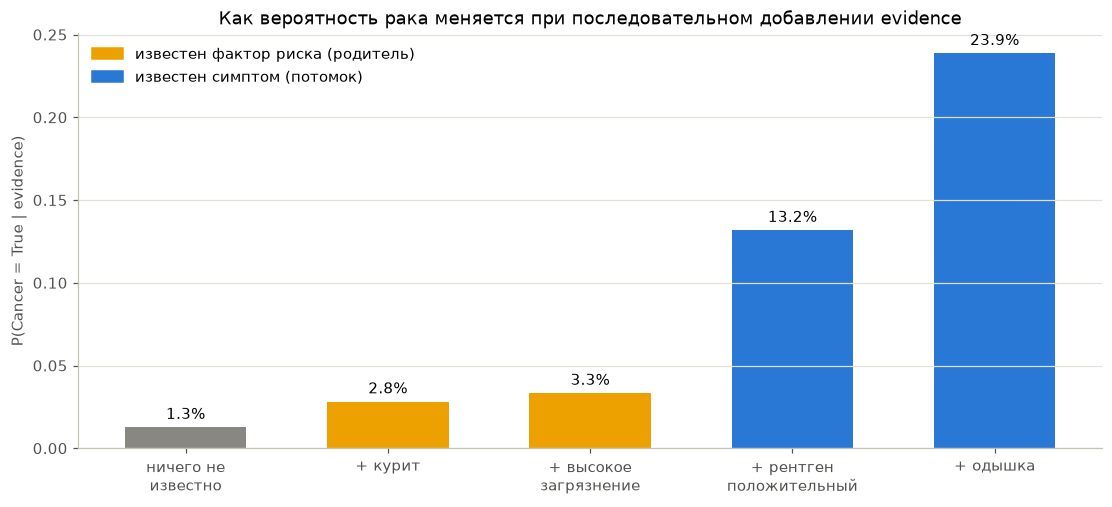

In [18]:
steps, accumulated = [], {}
for label, new_evidence in EVIDENCE_STEPS:
    accumulated = {**accumulated, **new_evidence}
    steps.append({
        "шаг": label,
        "evidence": evidence_text(accumulated),
        "P(Cancer=True | evidence)": prob(inference, TARGET, "True", accumulated),
        "наблюдений с таким evidence": count_rows(accumulated),
    })
evidence_table = pd.DataFrame(steps)
evidence_table["изменение (раз)"] = (evidence_table["P(Cancer=True | evidence)"]
                                    / evidence_table["P(Cancer=True | evidence)"].shift(1))
display(evidence_table.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
x = np.arange(len(evidence_table))
step_colors = [ROLE_COLORS["фактор риска"] if 0 < i < 3 else ROLE_COLORS["симптом / обследование"] if i >= 3
               else COLORS["data"] for i in range(len(x))]
bars = ax.bar(x, evidence_table["P(Cancer=True | evidence)"], color=step_colors, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in evidence_table["P(Cancer=True | evidence)"]], padding=3)
ax.set_xticks(x, [textwrap.fill(label, 16) for label in evidence_table["шаг"]])
ax.set_ylabel("P(Cancer = True | evidence)")
ax.set_title("Как вероятность рака меняется при последовательном добавлении evidence")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ROLE_COLORS["фактор риска"], label="известен фактор риска (родитель)"),
                   plt.Rectangle((0, 0), 1, 1, color=ROLE_COLORS["симптом / обследование"],
                                 label="известен симптом (потомок)")], frameon=False, loc="upper left")
plt.show()

In [19]:
# Вывод вручную для последнего шага: P(C | Smoker, Pollution, Xray, Dyspnoea) ∝ P(C | p, s) P(Xray | C) P(Dyspnoea | C)
p_dyspnoea = cpd_frame(model.get_cpds("Dyspnoea"))
last = {c: p_cancer.loc[c, ("high", "True")] * p_xray.loc["positive", c] * p_dyspnoea.loc["True", c]
        for c in ["True", "False"]}
for c, w in last.items():
    print(f"Cancer={c}: {p_cancer.loc[c, ('high', 'True')]:.4f} × {p_xray.loc['positive', c]:.4f} × "
          f"{p_dyspnoea.loc['True', c]:.4f} = {w:.5f}")
print(f"После нормировки: P(Cancer=True | все evidence) = {last['True'] / sum(last.values()):.4f}")

# d-разделение: когда Cancer известен, симптомы больше ничего не говорят о курении
display(run_queries("Smoker", "True", [
    {"Cancer": "True"},
    {"Cancer": "True", "Xray": "positive"},
    {"Cancer": "True", "Xray": "positive", "Dyspnoea": "True"},
]).round(4))

Cancer=True: 0.0333 × 0.9091 × 0.6364 = 0.01928
Cancer=False: 0.9667 × 0.2064 × 0.3082 = 0.06150
После нормировки: P(Cancer=True | все evidence) = 0.2387


,сеть,отношение к P без evidence,наблюдений с таким evidence
запрос,,,
P(Smoker=True | Cancer=True),0.6204,1.0,9
"P(Smoker=True | Cancer=True, Xray=positive)",0.6204,1.0,9
"P(Smoker=True | Cancer=True, Xray=positive, Dyspnoea=True)",0.6204,1.0,6


**Что происходит на каждом шаге и почему (через структуру сети).**

* **Шаги «курит» и «высокое загрязнение» — информация о родителях `Cancer`.** Вероятность просто берётся из нужного столбца таблицы `P(Cancer | Pollution, Smoker)`: сначала усредняется по `Pollution`, затем, когда известны оба родителя, остаётся одна ячейка (0.033). Эти шаги меняют вероятность умеренно: ×2.2 и ×1.2.
* **Шаги «рентген» и «одышка» — информация о потомках `Cancer`.** Вывод идёт «против стрелок»: $P(Cancer \mid e) \propto P(Cancer, e)$. Для каждого состояния `Cancer` вес умножается на вероятность наблюдённого симптома, затем веса нормируются. Ручной расчёт выше даёт те же 23.9%, что и `VariableElimination`. Симптомы при известном `Cancer` независимы (развилка), поэтому их вклады перемножаются независимо друг от друга.
* **Обследование информативнее факторов риска:** два симптома подняли вероятность в ~7 раз (3.3% → 23.9%), а два фактора риска — в ~2.6 раза.
* Дополнительная информация может и повышать, и понижать вероятность. Например, отрицательный рентген снизил бы её почти в 9 раз (вопрос 2).
* Даже при всех четырёх «плохих» признаках вероятность рака — 24%: отсутствие рака по-прежнему вероятнее.
* **Число наблюдений.** Под условие последнего шага в данных подходит **1** человек. Прямой подсчёт по данным здесь бессмыслен, а сеть даёт ответ, комбинируя локальные таблицы, каждая из которых оценена по большему числу наблюдений. Это главное преимущество факторизации. Но точность ответа ограничена точностью этих таблиц, в первую очередь ячейки `P(Cancer | high, курит)` (0 из 28).
* **Нижняя таблица:** когда `Cancer` известен, симптомы больше не меняют вероятность курения (62% во всех строках). По d-разделению наблюдаемый `Cancer` блокирует цепи `Smoker → Cancer → симптом`.

## 9. Анализ структуры

### Удаление ребра `Smoker → Cancer`

Удаляем ребро, заново оцениваем параметры изменённого графа по тем же данным и повторяем запросы вопросов 1 и 3.

In [20]:
reduced_edges = [edge for edge in EDGES if edge != REMOVED_EDGE]
model_reduced = fit_network(reduced_edges, DiscreteBayesianEstimator(prior_type="dirichlet", pseudo_counts=PSEUDO_COUNT))
reduced_inference = VariableElimination(model_reduced)


def compare_structures(variable, state, evidences):
    return pd.DataFrame({
        "исходная сеть": [prob(inference, variable, state, ev) for ev in evidences],
        f"без {REMOVED_EDGE[0]} → {REMOVED_EDGE[1]}": [prob(reduced_inference, variable, state, ev) for ev in evidences],
    }, index=[f"P({variable}={state} | {evidence_text(ev)})" for ev in evidences])


display(compare_structures("Cancer", "True", [{}, {"Smoker": "True"}, {"Smoker": "True", "Pollution": "high"}]).round(4))
display(compare_structures("Smoker", "True", [{}, {"Cancer": "True"}, {"Cancer": "True", "Pollution": "high"}]).round(4))
print("Локальная таблица P(Cancer | Pollution) в сети без ребра:")
display(cpd_frame(model_reduced.get_cpds("Cancer")).round(4))

,исходная сеть,без Smoker → Cancer
P(Cancer=True | —),0.0127,0.0109
P(Cancer=True | Smoker=True),0.0282,0.0109
"P(Cancer=True | Smoker=True, Pollution=high)",0.0333,0.0265


,исходная сеть,без Smoker → Cancer
P(Smoker=True | —),0.2804,0.2804
P(Smoker=True | Cancer=True),0.6204,0.2804
"P(Smoker=True | Cancer=True, Pollution=high)",0.2691,0.2804


Локальная таблица P(Cancer | Pollution) в сети без ребра:


Pollution,high,low
Cancer,,
False,0.9735,0.991
True,0.0265,0.009


**Изменился ли результат?** Да, принципиально.
* Без ребра `P(Cancer | Smoker = True)` = `P(Cancer)` = 1.09%: курение больше не несёт информации о раке. Сеть теперь утверждает `Cancer ⟂ Smoker | Pollution`, и никакие данные это не исправят — в ней просто нет параметров, которые описывали бы зависимость от курения.
* Исчез и explaining away из вопроса 3: `P(Smoker | Cancer)` = `P(Smoker)` = 28%, и загрязнение больше ничего не меняет. Коллайдера `Pollution → Cancer ← Smoker` больше нет, `Smoker` стал изолированной вершиной.
* Изменилась и локальная таблица `Cancer`: вместо `P(Cancer | Pollution, Smoker)` с 4 столбцами теперь `P(Cancer | Pollution)` с 2 столбцами, где курящие и некурящие смешаны. Поэтому немного изменилась даже безусловная `P(Cancer)` (1.27% → 1.09%): сглаживание «+1» теперь добавляется к меньшему числу ячеек.
* Выводы, которые не проходят через удалённое ребро (влияние загрязнения, диагностика по симптомам), почти не изменились.

**Почему структура графа влияет на вывод.** Граф определяет факторизацию — какие локальные таблицы оцениваются и перемножаются — и тем самым набор условных независимостей. Удалив ребро, мы запретили модели «видеть» зависимость рака от курения, хотя в данных она есть (2.1% у курящих против 0.4% у некурящих).

### Можно ли выбрать структуру только по данным?

Для сравнения запустим два подхода к поиску структуры по данным, без знаний о предметной области: оптимизацию score графа (Hill Climbing с BIC — правдоподобие со штрафом за число параметров) и тесты условной независимости (PC-алгоритм с χ²).

Hill Climbing + BIC    [('Cancer', 'Xray')] | без направления: []
PC (тесты χ²)          [('Smoker', 'Cancer'), ('Xray', 'Cancer')] | без направления: []


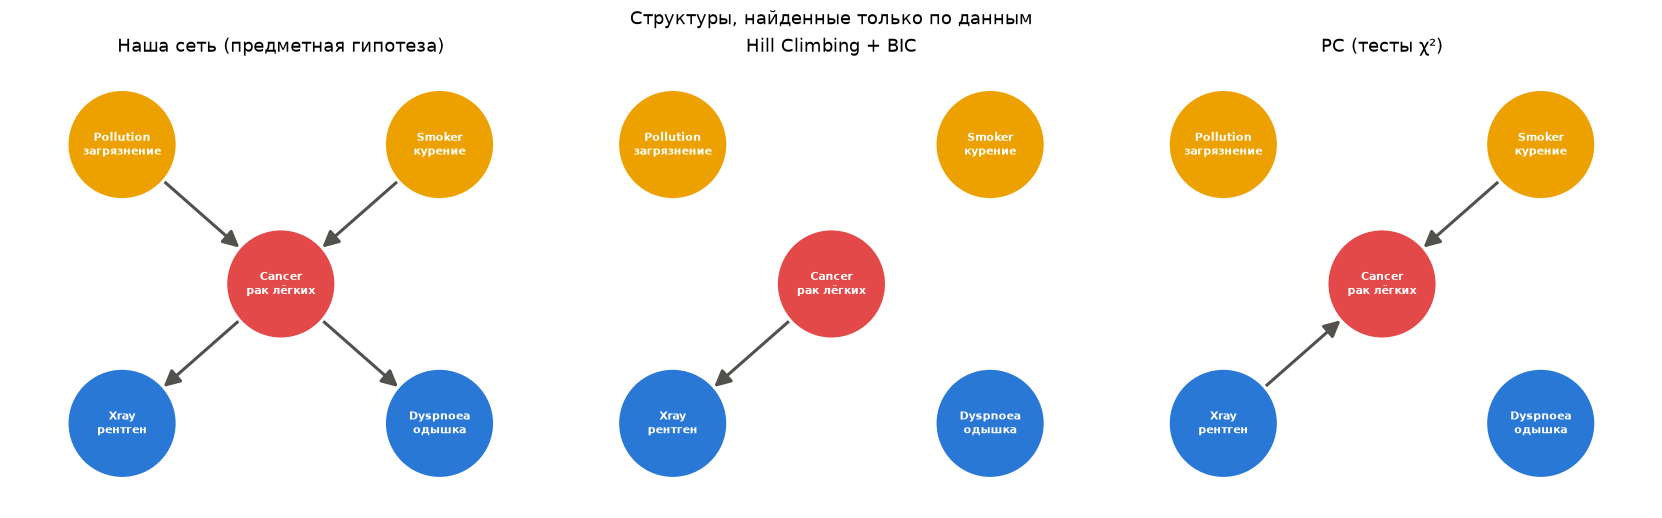

In [21]:
bic_dag = HillClimbSearch(data).estimate(scoring_method="bic-d", show_progress=False)
pc_pdag = PC(data).estimate(ci_test="chi_square", significance_level=PC_SIGNIFICANCE, return_type="pdag",
                            show_progress=False)
pc_undirected = list(pc_pdag.undirected_edges)

learned = {
    "Hill Climbing + BIC": (list(bic_dag.edges()), []),
    "PC (тесты χ²)": (list(pc_pdag.directed_edges) + pc_undirected, pc_undirected),
}
for name, (edges, undirected) in learned.items():
    print(f"{name:<22}", sorted(edges), "| без направления:", undirected)

fig, axes = plt.subplots(1, len(learned) + 1, figsize=(15, 4.6), layout="constrained")
draw_network(axes[0], EDGES, "Наша сеть (предметная гипотеза)")
for ax, (name, (edges, undirected)) in zip(axes[1:], learned.items()):
    draw_network(ax, edges, name, undirected=undirected)
fig.suptitle("Структуры, найденные только по данным")
plt.show()

**Что нашли алгоритмы.**
* **BIC** оставил единственное ребро `Cancer → Xray`. Штраф за число параметров перевесил выигрыш в правдоподобии для всех остальных рёбер: любое ребро, связанное с раком, подтверждается всего 9 наблюдениями. Направление этого единственного ребра данные определить не могут: граф `Xray → Cancer` описывает то же самое распределение.
* **PC** нашёл коллайдер `Smoker → Cancer ← Xray`. По смыслу это абсурд: рентген не может быть *причиной* рака. Ориентация возникла из-за шума в тестах независимости на крошечных подвыборках.

**Насколько уверенно можно выбирать направление рёбер только по наблюдаемым данным.** Неуверенно. Разные графы могут быть **марковски эквивалентны**: например, цепь `Smoker → Cancer → Xray`, развилка `Smoker ← Cancer → Xray` и цепь `Smoker ← Cancer ← Xray` имеют одинаковый скелет, у них нет коллайдеров, и все они задают одну и ту же независимость `Smoker ⟂ Xray | Cancer`. По наблюдательным данным такие графы не различить даже при очень большом датасете. Различимы только коллайдеры (`Pollution → Cancer ← Smoker`): две величины независимы, но становятся зависимыми при известном общем следствии. Но в нашей выборке этот сигнал живёт среди 9 больных, и алгоритмы его не видят.

Вывод: высокая корреляция сама по себе не выбирает направление ребра. Структуру разумно строить как предметную гипотезу, объясняя каждое ребро, а данные использовать для проверки этой гипотезы и оценки параметров.

## 10. Причинность

**В общем случае — нет.** Байесовская сеть, обученная по наблюдательным данным, — модель совместного распределения. Стрелки задают его факторизацию и набор условных независимостей. Как показано в разделе 9, одно и то же распределение можно описать марковски эквивалентными графами с другими направлениями стрелок. Поэтому направленная стрелка сама по себе не доказывает причинно-следственную связь.

**Какие связи мы считаем причинными и на каком основании.** Основание всегда внешнее по отношению к данным:
* `Smoker → Cancer` и `Pollution → Cancer` — многочисленные медицинские исследования, порядок во времени (курение и условия жизни предшествуют болезни) и понятный механизм (канцерогены в дыме и загрязнённом воздухе). Кроме того, загрязнение — внешнее условие, на которое болезнь человека повлиять не может;
* `Cancer → Xray`, `Cancer → Dyspnoea` — физический механизм: снимок и симптом — следствия состояния лёгких.

**Наблюдение и вмешательство.** `P(Cancer | Smoker = True)` — вероятность рака у тех, *кого мы наблюдаем* курящими. `P(Cancer | do(Smoker = True))` — вероятность рака, если *заставить* человека курить. При принятой причинной модели у `Smoker` нет родителей, поэтому эти величины совпадают. Обратный пример из той же сети: `P(Smoker | Cancer = True)` = 62%, а `P(Smoker | do(Cancer = True))` = 28%. Если бы мы сами «вызвали» рак, это ничего не сказало бы о привычках человека: вмешательство отрезает стрелки, входящие в `Cancer`. Такие do-вычисления верны только если принятая причинная модель правильна.

**Где модель может обмануть.** Главная угроза — **скрытая общая причина**. В реальной выборке она почти наверняка есть: возраст влияет и на стаж курения, и на риск рака; район проживания связан и с загрязнением, и с привычками. Скрытая общая причина создаёт зависимость между наблюдаемыми узлами: предположение `Pollution ⟂ Smoker` нарушилось бы, а `P(Cancer | Smoker)` смешивала бы эффект курения с эффектом возраста. В нашей сети таких переменных нет, поэтому причинная интерпретация возможна только при сильном предположении, что важных скрытых причин нет.

## 11. Итог

* **Что удалось узнать.** Рак лёгких в выборке редок (~1%). Факторы риска повышают его вероятность в разы, но в абсолютных числах она остаётся порядка нескольких процентов. Результаты обследования информативнее факторов риска: положительный рентген даёт ~5%, рентген вместе с одышкой — ~10%, все четыре «плохих» признака — ~24%. Отрицательный рентген снижает вероятность почти в 9 раз.
* **Самые интересные зависимости:**
  * **explaining away** на коллайдере `Pollution → Cancer ← Smoker`: независимые факторы риска становятся зависимыми, когда известен диагноз;
  * редкость болезни: даже при положительном рентгене рака, скорее всего, нет, потому что здоровых с ложноположительным снимком намного больше, чем больных;
  * **d-разделение:** курение не влияет на одышку, если известно, что рака нет, а симптомы ничего не говорят о курении, если диагноз известен.
* **Как evidence влияет на вероятности.** Информация о родителях выбирает столбец локальной таблицы. Информация о потомках обновляет вероятность через $P(Cancer \mid e) \propto P(Cancer, e)$ с последующей нормировкой. Информация может как повышать, так и понижать вероятность. Наблюдаемый неколлайдер блокирует путь, а наблюдаемый коллайдер — открывает.
* **Насколько результаты зависят от структуры.** Сильно. Удаление одного ребра полностью убирает соответствующую зависимость из всех выводов, и данные не могут её «вернуть». Структуры, найденные только по данным, зависят от метода и местами бессмысленны (рентген как причина рака). Направления рёбер берутся из знаний о предметной области.
* **Ограничения модели:**
  * данные синтетические — сеть воспроизводит заложенную схему, а не реальную медицину;
  * всего 9 случаев рака: все параметры, связанные с больными, неточны. Ячейка `P(Cancer | high, курит)` (0 из 28) занижает эффект курения и искажает explaining away. Сглаживание Лапласа убирает нули, но завышает самые редкие вероятности;
  * слишком грубые категории: бинарные переменные скрывают различия внутри категории (интенсивность и стаж курения, уровень загрязнения);
  * нет возможных скрытых общих причин (возраст, район проживания) и других болезней, вызывающих одышку. Поэтому причинная интерпретация требует сильных предположений;
  * пропусков в данных нет — в реальных данных они потребовали бы отдельной стратегии оценки параметров.